# ENG2440 Assignment 2: Tumor Segmentation in MRI Volumes

Name: Md Aman Khan

Student ID: 25011138

Imports

In [1]:
from scripts.preprocessing import normalize_channels, crop_to_box, augment
from scripts.dataset import cache_case, PatchDataset
from scripts.model import UNet3D
from scripts.training import train_model
from scipy.stats import wilcoxon
from scripts.inference import predict_volume, window_starts, remove_small_components, keep_largest_component
from scripts.evaluation import overlap_metrics, case_metrics
from scripts.plots import centroid_point, largest_error_point, plot_contour_rows, plot_error_rows

from pathlib import Path
import pandas as pd
import hashlib
import time

import json
import numpy as np
import nibabel as nib

import matplotlib.pyplot as plt

from scipy.ndimage import zoom, label as label_components

import torch
from torch.utils.data import DataLoader

Configuration

In [2]:
DATA_ROOT = Path("Task01_BrainTumour")
SPLIT_FILE = Path("assignment2_split.csv")
CHECKPOINT_DIR = Path("checkpoints")
SEED = 42

CACHE_DIR = Path("cache")
PATCH_SIZE = (64, 64, 64)
BATCH_SIZE = 4

DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

EPOCHS = 20
ITERATIONS_PER_EPOCH = 50
LEARNING_RATE = 1e-3
VAL_PATCHES = 100

STRIDE = (32, 32, 32) 

Verify setup

In [3]:
split_df = pd.read_csv(SPLIT_FILE)

assert len(split_df) == 484
assert set(split_df["split"]) == {"train", "validation", "test"}

for row in split_df.itertuples():
    assert (DATA_ROOT / row.image_relpath).exists()
    assert (DATA_ROOT / row.label_relpath).exists()
    
print(split_df["split"].value_counts())

split
train         338
test           73
validation     73
Name: count, dtype: int64


### Part A. Define the task and inspect the volumes

State the input, output, unit of analysis and intended technical use. Distinguish a voxel, slice, volume and patient case.

**Input**: Multimodal 3D brain MRI of a patient, stored as NIfTI files. Each case has four co-registered channels (FLAIR, T1, T1ce and T2). Each of them being a 240x240x155 volume at 1mm spacing. The model is trained on small 3D patches from these volumes and applied to the full volume at inference time.

**Output**: A binary 3D mask with the same shape and geometry as the input. A voxel is 1 if it is predicted to be a whole tumor and 0 otherwise. The model first outputs a per-voxel tumor probability and then it is thresholded to get the mask.

**Unit of analysis**: The patient case (one volume per patient). Splitting and evaluation are done per case. Voxels and patches are what the model learns from.

**Intended technical use**: An exercise that outlines whole tumor so overlap and boundary quality can be measured against a reference segmentation. It is not an industry grade clinical tool and is not clinically validated.

- **Voxel**: a single 1x1x1 mm point with four intensities and one label.
- **Slice**: a 2D cross-section of a volume used for viewing.
- **Volume**: the full 3D scan with an affine that maps it to physical coordinates.
- **Patient case**: one patient with all four modalities and the label.


Load at least three cases. Report array shape, channel order, affine matrix, orientation codes, voxel spacing and label values.

In [4]:
with open(DATA_ROOT / "dataset.json") as f:
    dataset_info = json.load(f)

channel_order = [dataset_info["modality"][k] for k in sorted(dataset_info["modality"])]
print("Channel order:", channel_order)


Channel order: ['FLAIR', 'T1w', 't1gd', 'T2w']


In [5]:
for row in split_df[split_df["split"] == "train"].head(3).itertuples():
    image = nib.load(DATA_ROOT / row.image_relpath)
    label = nib.load(DATA_ROOT / row.label_relpath)

    print(f"\n{row.case_id}")
    print("Image shape:", image.shape, "| Label shape:", label.shape)
    print("Affine:\n", np.round(image.affine, 2))
    print("Orientation codes:", nib.aff2axcodes(image.affine))
    print("Voxel spacing (mm):", tuple(float(z) for z in image.header.get_zooms()[:3]))
    print("Label values:", np.unique(label.get_fdata()).astype(int))


BRATS_001
Image shape: (240, 240, 155, 4) | Label shape: (240, 240, 155)
Affine:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Orientation codes: ('R', 'A', 'S')
Voxel spacing (mm): (1.0, 1.0, 1.0)
Label values: [0 1 2 3]

BRATS_003
Image shape: (240, 240, 155, 4) | Label shape: (240, 240, 155)
Affine:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Orientation codes: ('R', 'A', 'S')
Voxel spacing (mm): (1.0, 1.0, 1.0)
Label values: [0 1 2 3]

BRATS_004
Image shape: (240, 240, 155, 4) | Label shape: (240, 240, 155)
Affine:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Orientation codes: ('R', 'A', 'S')
Voxel spacing (mm): (1.0, 1.0, 1.0)
Label values: [0 1 2 3]


For one case, display FLAIR, T1, T1ce and T2 at the same physical location, plus the reference mask.

In [6]:
case = split_df[split_df["split"] == "train"].iloc[0]

image = nib.load(DATA_ROOT / case.image_relpath)
label = nib.load(DATA_ROOT / case.label_relpath)

image_data = image.get_fdata()
label_data = label.get_fdata().astype(int)

In [7]:
z = int(np.argmax((label_data > 0).sum(axis=(0, 1))))

print(case.case_id, "| axial slice index:", z, "| physical z (mm):", image.affine[2, 2] * z + image.affine[2, 3])

BRATS_001 | axial slice index: 63 | physical z (mm): 63.0


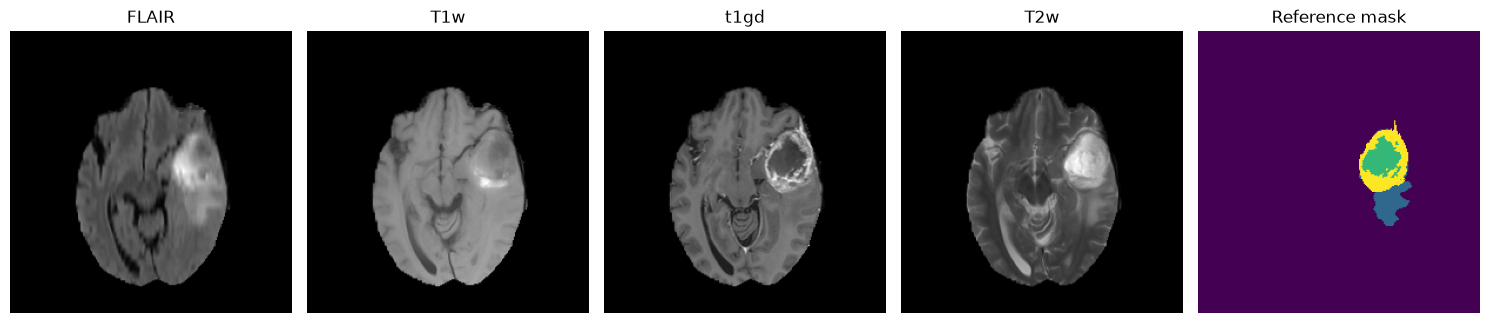

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.5))

for i, name in enumerate(channel_order):
    axes[i].imshow(image_data[:, :, z, i].T, cmap="gray", origin="lower")
    axes[i].set_title(name)

axes[4].imshow(label_data[:, :, z].T, cmap="viridis", origin="lower", vmin=0, vmax=3)
axes[4].set_title("Reference mask")

for ax in axes:
    ax.axis("off")
    
plt.tight_layout()
plt.show()

Display the reference in axial, coronal and sagittal planes and explain why file-index order alone is insufficient for spatial interpretation.

In [9]:
x, y, z = np.round(np.argwhere(label_data > 0).mean(axis=0)).astype(int)

print("Center voxel (i, j, k):", (x, y, z))
print("Physical position (mm):", nib.affines.apply_affine(image.affine, (x, y, z)))
print("Orientation codes:", nib.aff2axcodes(image.affine))

Center voxel (i, j, k): (np.int64(157), np.int64(116), np.int64(67))
Physical position (mm): [157. 116.  67.]
Orientation codes: ('R', 'A', 'S')


In [10]:
sx, sy, sz = image.header.get_zooms()[:3]

views = {
    "Axial": (image_data[:, :, z, 0].T, label_data[:, :, z].T, sy / sx),
    "Coronal": (image_data[:, y, :, 0].T, label_data[:, y, :].T, sz / sx),
    "Sagittal": (image_data[x, :, :, 0].T, label_data[x, :, :].T, sz / sy),
}

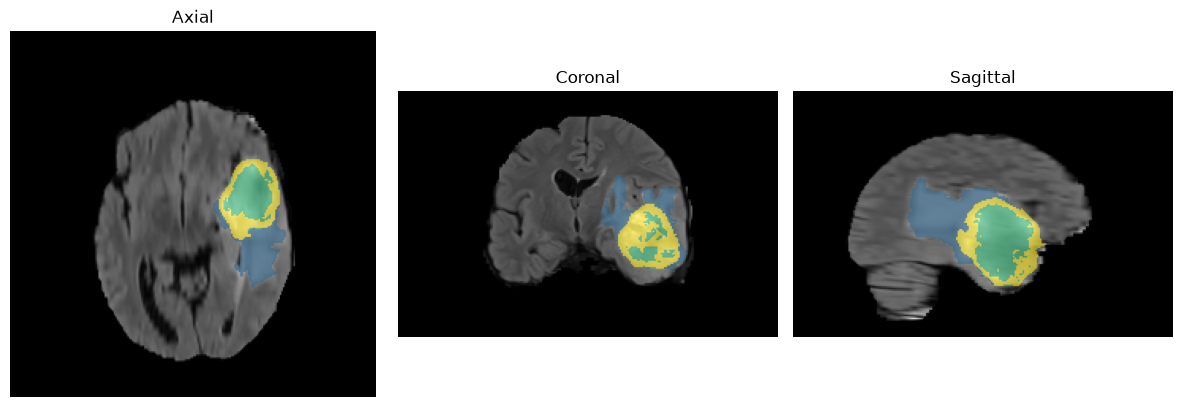

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, (name, (img, lab, aspect)) in zip(axes, views.items()):
    ax.imshow(img, cmap="gray", origin="lower", aspect=aspect)
    ax.imshow(np.ma.masked_where(lab == 0, lab), cmap="viridis", origin="lower", aspect=aspect, alpha=0.6, vmin=0, vmax=3)
    ax.set_title(name)
    ax.axis("off")
    
plt.tight_layout()
plt.show()

File-index order alone is not enough because the array axes [i, j, k] can only describe how the data is stored. They do not say which anatomical direction each axis points to. The affine matrix and orientation codes are needed to map voxel indices to physical positions in mm and to know which axis is left-right, front-back or up-down. Another file could have a different orientation or voxel spacing. So, the same index would then refer to a different location or give a stretched image. A slice index is also not a physical distance until it is multiplied by the voxel spacing.

### Part B. Create a reproducible case-level split

Verify that every listed image and label exists and that case identifiers are disjoint across train, validation and test.

In [12]:
missing_images = [p for p in split_df["image_relpath"] if not (DATA_ROOT / p).exists()]
missing_labels = [p for p in split_df["label_relpath"] if not (DATA_ROOT / p).exists()]

print("Missing images:", len(missing_images), "| Missing labels:", len(missing_labels))

assert not missing_images and not missing_labels

Missing images: 0 | Missing labels: 0


In [13]:
train_ids = set(split_df.loc[split_df["split"] == "train", "case_id"])
validation_ids = set(split_df.loc[split_df["split"] == "validation", "case_id"])
test_ids = set(split_df.loc[split_df["split"] == "test", "case_id"])

In [14]:
assert train_ids.isdisjoint(validation_ids)
assert train_ids.isdisjoint(test_ids)
assert validation_ids.isdisjoint(test_ids)
assert len(train_ids | validation_ids | test_ids) == len(split_df)

print("Train/validation/test case IDs are disjoint:", len(train_ids), len(validation_ids), len(test_ids))

Train/validation/test case IDs are disjoint: 338 73 73


Report case counts and the distribution of reference tumor volume in each split. Keep the test labels unused until final evaluation.

In [15]:
volumes = []

for row in split_df.itertuples():
    label = nib.load(DATA_ROOT / row.label_relpath)
    voxel_ml = np.prod(label.header.get_zooms()[:3]) / 1000
    volumes.append(np.count_nonzero(label.dataobj) * voxel_ml)
    
split_df["tumor_volume_ml"] = volumes

In [16]:
# counts and distribution
order = ["train", "validation", "test"]

print(split_df["split"].value_counts().reindex(order))
print(split_df.groupby("split")["tumor_volume_ml"].describe().reindex(order).round(1))

split
train         338
validation     73
test           73
Name: count, dtype: int64
            count   mean   std   min   25%   50%    75%    max
split                                                         
train       338.0  103.0  57.0   8.5  60.0  95.5  143.9  265.3
validation   73.0  100.8  63.0   7.3  51.9  91.6  148.1  266.9
test         73.0  107.4  66.3  10.1  54.4  89.1  157.7  318.3


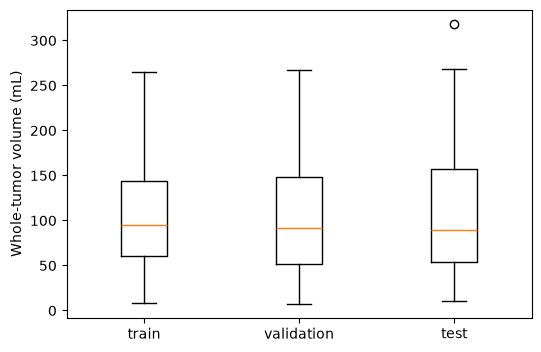

In [17]:
fig, ax = plt.subplots(figsize=(6, 4))

ax.boxplot([split_df.loc[split_df["split"] == s, "tumor_volume_ml"] for s in order], tick_labels=order)
ax.set_ylabel("Whole-tumor volume (mL)")

plt.show()

### Part C. Preprocess MRI and labels safely

Verify geometry across all four channels and the label. If resampling is needed, define one target grid and document it.

In [18]:
geometry_rows = []

for row in split_df.itertuples():
    image = nib.load(DATA_ROOT / row.image_relpath)
    label = nib.load(DATA_ROOT / row.label_relpath)
    geometry_rows.append({
        "case_id": row.case_id,
        "image_shape": image.shape[:3],
        "n_channels": image.shape[3],
        "label_shape": label.shape,
        "image_spacing": tuple(round(float(z), 3) for z in image.header.get_zooms()[:3]),
        "label_spacing": tuple(round(float(z), 3) for z in label.header.get_zooms()[:3]),
        "image_orientation": "".join(nib.aff2axcodes(image.affine)),
        "label_orientation": "".join(nib.aff2axcodes(label.affine)),
        "affine_match": bool(np.allclose(image.affine, label.affine)),
        "affine_is_identity": bool(np.allclose(image.affine, np.eye(4))),
    })
    
geometry_df = pd.DataFrame(geometry_rows)

for column in geometry_df.columns.drop("case_id"):
    print(column, geometry_df[column].value_counts().to_dict())

image_shape {(240, 240, 155): 484}
n_channels {4: 484}
label_shape {(240, 240, 155): 484}
image_spacing {(1.0, 1.0, 1.0): 484}
label_spacing {(1.0, 1.0, 1.0): 484}
image_orientation {'RAS': 484}
label_orientation {'RAS': 484}
affine_match {True: 484}
affine_is_identity {True: 484}


All 484 cases have the same geometry. Each image has 4 channels with shape 240x240x155 and 1x1x1 mm spacing, all in RAS orientation with an identity affine, and the label matches the image in shape, spacing, orientation and affine in all cases. because the four channels are stored in one file, they share a single grid with the label. Resampling is not needed, so the native grid (240x240x155, 1mm isotropic) is kept as the common target grid for all cases.

Use linear interpolation for MRI and nearest-neighbour interpolation for labels. Demonstrate that label values remain valid.

In [19]:
# demo resample
case = split_df[split_df["split"] == "train"].iloc[0]
image_data = nib.load(DATA_ROOT / case.image_relpath).get_fdata()
label_data = nib.load(DATA_ROOT / case.label_relpath).get_fdata().astype(np.uint8)

scale = 0.5  # 1 mm -> 2 mm

image_resampled = np.stack([zoom(image_data[..., c], scale, order=1) for c in range(image_data.shape[-1])], axis=-1)  # linear for MRI
label_nearest = zoom(label_data, scale, order=0)
label_linear = zoom(label_data.astype(np.float32), scale, order=1)

print("Original shape:", image_data.shape[:3], "-> resampled shape:", image_resampled.shape[:3])


Original shape: (240, 240, 155) -> resampled shape: (120, 120, 78)


In [20]:
print("Original label values:", np.unique(label_data))
print("Nearest-neighbour label values:", np.unique(label_nearest))
print("Linear-interpolated label values:", np.unique(label_linear).round(2)[:12], "...")
print("Number of non-integer voxels with linear:", np.count_nonzero(label_linear != np.round(label_linear)))

assert set(np.unique(label_nearest)).issubset({0, 1, 2, 3})


Original label values: [0 1 2 3]
Nearest-neighbour label values: [0 1 2 3]
Linear-interpolated label values: [0.   0.09 0.09 0.09 0.09 0.09 0.09 0.09 0.1  0.1  0.1  0.1 ] ...
Number of non-integer voxels with linear: 4039


Normalize each MRI channel using statistics from non-zero brain voxels, not the zero-padded background. Report the resulting mean and standard deviation.

In [21]:
case = split_df[split_df["split"] == "train"].iloc[0]
image_data = nib.load(DATA_ROOT / case.image_relpath).get_fdata().astype(np.float32)
normalized = normalize_channels(image_data)

In [22]:
rows = []

for c, name in enumerate(channel_order):
    raw, norm = image_data[..., c], normalized[..., c]

    brain = raw != 0
    
    rows.append({
        "channel": name,
        "brain_voxel_fraction": brain.mean(),
        "raw_mean": raw[brain].mean(), "raw_std": raw[brain].std(),
        "whole_volume_mean": raw.mean(), "whole_volume_std": raw.std(),
        "normalized_mean": norm[brain].mean(), "normalized_std": norm[brain].std(),
    })

print(pd.DataFrame(rows).set_index("channel").round(3).to_string())


         brain_voxel_fraction    raw_mean     raw_std  whole_volume_mean  whole_volume_std  normalized_mean  normalized_std
channel                                                                                                                    
FLAIR                   0.167  516.273987  211.647995          86.019997        210.889008              0.0             1.0
T1w                     0.167  780.635010  206.554993         130.182999        302.972992             -0.0             1.0
t1gd                    0.167  728.439026  239.416000         121.466003        288.591003             -0.0             1.0
T2w                     0.167  471.843994  211.000000          78.685997        195.858002             -0.0             1.0


Crop or pad consistently and apply safe training-only augmentation. Show one paired before/after example and justify the transforms.

In [23]:
image_crop = crop_to_box(normalize_channels(image_data))
label_crop = crop_to_box(label_data)

print("Before crop:", image_data.shape, "-> after crop:", image_crop.shape, label_crop.shape)
print("Brain voxels kept:", (image_data != 0).any(-1).sum() == (crop_to_box(image_data) != 0).any(-1).sum())
print("Tumor voxels kept:", label_data.sum() == label_crop.sum())

Before crop: (240, 240, 155, 4) -> after crop: (168, 192, 152, 4) (168, 192, 152)
Brain voxels kept: True
Tumor voxels kept: True


Label values after augmentation: [0 1 2 3]


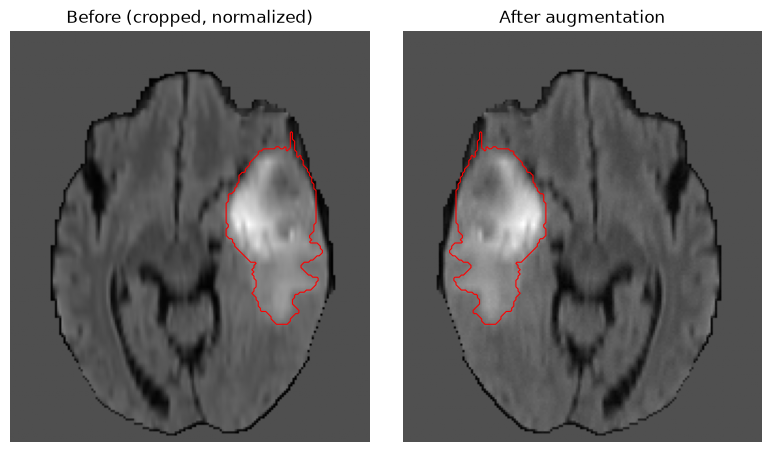

In [24]:
rng = np.random.default_rng(2)
image_aug, label_aug = augment(image_crop, label_crop, rng)
print("Label values after augmentation:", np.unique(label_aug))

z = int(np.argmax((label_crop > 0).sum(axis=(0, 1))))

fig, axes = plt.subplots(1, 2, figsize=(8, 4.5))
for ax, img, lab, title in zip(axes, [image_crop, image_aug], [label_crop, label_aug], ["Before (cropped, normalized)", "After augmentation"]):
    ax.imshow(img[:, :, z, 0].T, cmap="gray", origin="lower")
    ax.contour(lab[:, :, z].T > 0, levels=[0.5], colors="red", linewidths=0.8)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

All the volumes were cropped to a fixed box of 168x192x152 voxels. Starting at voxel (36, 19, 0). The box was chosen from the bounding box of the non-zero brain voxels across all cases (x 38-200, y 19-211, z 0-149), so no brain or tumor voxels are removed. It removes a huge part of the empty background which reduces memory and compute. Every dimension is a multiple of 8 so that the 3D U-Net can down sample and up sample without any size mismatches. The same box is applied to the image and the label so they stay aligned. Anywhere the box would leave the volume it is zero-padded.

Augmentation is applied to the training split only. A left-right flip is implemented with probability 0.5 to the image and label together, as the brain is approximately symmetric and the tumor can appear on either side. Each channel also receives a small random intensity scale (0.9 to 1.1), shift (-0.1 to 0.1) and gaussian noise (std deviation 0.05), applied to brain voxels only so the background stays 0. This simulates any scanner and acquisition differences. These intensity changes are applied only to the image and never to the label. Rotations, scaling and elastic deformation are not used because they require interpolating the label and could introduce invalid label values or distort tumor boundaries. Flips along any other axes are not used because they are not anatomically possible ( for example upside-down brains ).

### Part D. Implement patch-based volumetric training

Implement a PyTorch Dataset and DataLoader returning tensors shaped [C, D, H, W] and binary masks shaped [1, D, H, W]. Print and verify one batch.

In [25]:
CACHE_DIR.mkdir(exist_ok=True)

for row in split_df.itertuples():
    cache_case(row, DATA_ROOT, CACHE_DIR)
    
print("Cached cases:", len(list(CACHE_DIR.glob("*_image.npy"))))

Cached cases: 484


In [26]:
train_cases = split_df.loc[split_df["split"] == "train", "case_id"].tolist()

train_dataset = PatchDataset(train_cases, CACHE_DIR, PATCH_SIZE, sampling="uniform", seed=SEED)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

images, masks = next(iter(train_loader))

print("Image batch [B, C, D, H, W]:", tuple(images.shape), images.dtype)
print("Mask batch  [B, 1, D, H, W]:", tuple(masks.shape), masks.dtype)
print("Mask values:", masks.unique().tolist())
print("Fraction of tumor voxels in batch:", round(masks.mean().item(), 4))

Image batch [B, C, D, H, W]: (4, 4, 64, 64, 64) torch.float32
Mask batch  [B, 1, D, H, W]: (4, 1, 64, 64, 64) torch.float32
Mask values: [0.0, 1.0]
Fraction of tumor voxels in batch: 0.0008


In [27]:
assert images.shape[1:] == (4, *PATCH_SIZE) and masks.shape[1:] == (1, *PATCH_SIZE)
assert set(masks.unique().tolist()) <= {0.0, 1.0}

Build a lightweight 3D U-Net or equivalent fully convolutional 3D model. Report input channels, output channels, parameter count and patch size.

In [28]:
torch.manual_seed(SEED)
model = UNet3D(in_channels=4, out_channels=1, base_filters=16).to(DEVICE)

n_params = sum(p.numel() for p in model.parameters())

print("Input channels:", 4)
print("Output channels:", 1)
print("Patch size (D, H, W):", PATCH_SIZE)
print("Trainable parameters:", n_params)
print("Device:", DEVICE)

Input channels: 4
Output channels: 1
Patch size (D, H, W): (64, 64, 64)
Trainable parameters: 1402561
Device: mps


In [29]:
model.eval()

with torch.no_grad():
    logits = model(images.to(DEVICE))
    
print("Input batch:", tuple(images.shape), "-> output logits:", tuple(logits.shape))
assert logits.shape == (images.shape[0], 1, *PATCH_SIZE)

Input batch: (4, 4, 64, 64, 64) -> output logits: (4, 1, 64, 64, 64)


Train first with uniform random patches. State the loss, optimizer, learning rate, epoch/iteration budget and random seed.

In [30]:
validation_cases = split_df.loc[split_df["split"] == "validation", "case_id"].tolist()

train_dataset = PatchDataset(train_cases, CACHE_DIR, PATCH_SIZE, sampling="uniform",
                             samples_per_epoch=ITERATIONS_PER_EPOCH * BATCH_SIZE, seed=SEED)
val_dataset = PatchDataset(validation_cases, CACHE_DIR, PATCH_SIZE, sampling="uniform",
                           train=False, samples_per_epoch=VAL_PATCHES, seed=SEED + 1)

In [31]:
CHECKPOINT_DIR.mkdir(exist_ok=True)
UNIFORM_CHECKPOINT = CHECKPOINT_DIR / "unet_uniform.pt"

torch.manual_seed(SEED)
model_uniform = UNet3D(in_channels=4, out_channels=1, base_filters=16).to(DEVICE)

if UNIFORM_CHECKPOINT.exists():
    checkpoint = torch.load(UNIFORM_CHECKPOINT, map_location=DEVICE, weights_only=False)
    model_uniform.load_state_dict(checkpoint["model_state"])
    history_uniform = checkpoint["history"]
    print("Loaded checkpoint:", UNIFORM_CHECKPOINT)
else:
    model_uniform, history_uniform = train_model(
        model_uniform, train_dataset, val_dataset, DEVICE,
        epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LEARNING_RATE, checkpoint_path=UNIFORM_CHECKPOINT,
    )

Loaded checkpoint: checkpoints/unet_uniform.pt


In [32]:
print("Sampler: uniform random patches")
print("Loss: BCE-with-logits + soft Dice")
print("Optimizer: Adam | learning rate:", LEARNING_RATE)
print("Budget:", EPOCHS, "epochs x", ITERATIONS_PER_EPOCH, "iterations =", EPOCHS * ITERATIONS_PER_EPOCH,
      "iterations of batch size", BATCH_SIZE)
print("Random seed:", SEED)
print("Best validation Dice:", round(history_uniform["val_dice"].max(), 4))

Sampler: uniform random patches
Loss: BCE-with-logits + soft Dice
Optimizer: Adam | learning rate: 0.001
Budget: 20 epochs x 50 iterations = 1000 iterations of batch size 4
Random seed: 42
Best validation Dice: 0.8182


The model was first trained using uniform random patches of size 64x64x64. The loss used was binary cross-entropy (BCE) with logits combined with a soft Dice loss, optimized using Adam with a learning rate of 1e-3. The training budget was 20 epochs of 50 iterations each (1000 iterations in total) with a batch size of 4. The random seed was 42, which also fixes the model initialization and the patches that are sampled. After each epoch the model was evaluated on 100 fixed validation patches and the weights with the highest validation Dice were kept.

Train the same model with tumor-aware patch sampling. Keep initialization and training budget controlled. Report the fraction of sampled patches containing tumor for both samplers.

In [33]:
train_dataset_tumor = PatchDataset(train_cases, CACHE_DIR, PATCH_SIZE, sampling="tumor_aware", tumor_prob=0.5,
                                   samples_per_epoch=ITERATIONS_PER_EPOCH * BATCH_SIZE, seed=SEED)

In [34]:
TUMOR_CHECKPOINT = CHECKPOINT_DIR / "unet_tumor_aware.pt"

torch.manual_seed(SEED)
model_tumor = UNet3D(in_channels=4, out_channels=1, base_filters=16).to(DEVICE)

if TUMOR_CHECKPOINT.exists():
    checkpoint = torch.load(TUMOR_CHECKPOINT, map_location=DEVICE, weights_only=False)
    model_tumor.load_state_dict(checkpoint["model_state"])
    history_tumor = checkpoint["history"]
    print("Loaded checkpoint:", TUMOR_CHECKPOINT)
else:
    model_tumor, history_tumor = train_model(
        model_tumor, train_dataset_tumor, val_dataset, DEVICE,
        epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LEARNING_RATE, checkpoint_path=TUMOR_CHECKPOINT,
    )

Loaded checkpoint: checkpoints/unet_tumor_aware.pt


In [35]:
def tumor_patch_fraction(dataset, epochs):
    hits = 0
    for epoch in range(epochs):
        dataset.set_epoch(epoch)
        hits += sum(dataset.contains_tumor(i) for i in range(len(dataset)))
    dataset.set_epoch(0)
    return hits / (epochs * len(dataset))

n_patches = EPOCHS * len(train_dataset)

print(f"Patches sampled over the full training budget: {n_patches}")
print("Uniform sampler: fraction of patches containing tumor =", round(tumor_patch_fraction(train_dataset, EPOCHS), 4))
print("Tumor-aware sampler: fraction of patches containing tumor =", round(tumor_patch_fraction(train_dataset_tumor, EPOCHS), 4))

Patches sampled over the full training budget: 4000
Uniform sampler: fraction of patches containing tumor = 0.6787
Tumor-aware sampler: fraction of patches containing tumor = 0.843


In [36]:
print("Seed:", SEED, "| Epochs:", EPOCHS, "| Iterations/epoch:", ITERATIONS_PER_EPOCH, "| Batch size:", BATCH_SIZE, "| LR:", LEARNING_RATE)
print("Only the sampler differs: uniform vs tumor-aware (tumor_prob = 0.5)")
print("Best validation Dice | uniform:", round(history_uniform["val_dice"].max(), 4), "| tumor-aware:", round(history_tumor["val_dice"].max(), 4))

Seed: 42 | Epochs: 20 | Iterations/epoch: 50 | Batch size: 4 | LR: 0.001
Only the sampler differs: uniform vs tumor-aware (tumor_prob = 0.5)
Best validation Dice | uniform: 0.8182 | tumor-aware: 0.8496


Plot training and validation loss and validation Dice. Identify underfitting, instability or overfitting without using test results for selection.

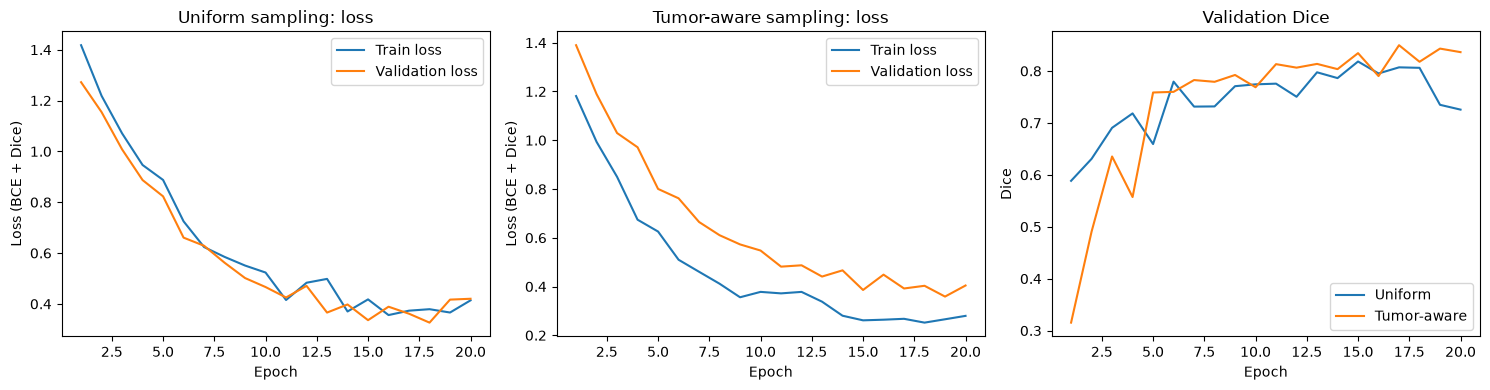

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, history, title in zip(axes[:2], [history_uniform, history_tumor],
                              ["Uniform sampling: loss", "Tumor-aware sampling: loss"]):
    ax.plot(history["epoch"], history["train_loss"], label="Train loss")
    ax.plot(history["epoch"], history["val_loss"], label="Validation loss")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss (BCE + Dice)")
    ax.legend()

axes[2].plot(history_uniform["epoch"], history_uniform["val_dice"], label="Uniform")
axes[2].plot(history_tumor["epoch"], history_tumor["val_dice"], label="Tumor-aware")
axes[2].set_title("Validation Dice")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Dice")
axes[2].legend()

plt.tight_layout()
plt.show()

The training and validation losses for the uniform sampler decreased together from about 1.4 to about 0.4 and stayed close to each other, so no clear sign of overfitting. The validation dice increased to 0.818 at epoch 15 but then dropped to 0.726 by epoch 20. The validation loss also went up slightly in the last two epochs. The training loss did not continue to decrease in this period so this looks like instability from a small batch size of 4, a constant learning rate and a validation set of only 100 patches. The losses were also still decreasing at the end of training, which suggests that the model is slightly undertrained because of the small training budget.

The tumor aware sampler showed a similar trend. The validation dice reached 0.850 at epoch 17 and had some fluctuations (for e.g. at epochs 4, 14, 16). Its training loss was lower than its validation loss by about 0.1 to 0.15. This is not necessarily overfitting because the training patches were chosen to contain more tumor than the uniformly sampled validation patches, so the two losses are measured on different patch distributions. Model selection uses the validation dice only and the test split was not used at any point.

### Part E. Controlled sampling comparison

Compare uniform and tumor-aware sampling using the same architecture, split, loss and training budget.

In [38]:
torch.manual_seed(SEED)
init_a = UNet3D(in_channels=4, out_channels=1, base_filters=16).state_dict()
torch.manual_seed(SEED)
init_b = UNet3D(in_channels=4, out_channels=1, base_filters=16).state_dict()
print("Identical initial weights for both runs:", all(torch.equal(init_a[k], init_b[k]) for k in init_a))

Identical initial weights for both runs: True


In [39]:
def summarize(history, dataset):
    best = history.loc[history["val_dice"].idxmax()]
    
    return {
        "Architecture": f"3D U-Net ({n_params / 1e6:.2f}M params)",
        "Loss": "BCE + soft Dice",
        "Optimizer": f"Adam, lr {LEARNING_RATE}",
        "Training budget": f"{EPOCHS} epochs x {ITERATIONS_PER_EPOCH} iterations, batch {BATCH_SIZE}",
        "Seed": SEED,
        "Patches with tumor": round(tumor_patch_fraction(dataset, EPOCHS), 3),
        "Best epoch (val Dice)": int(best["epoch"]),
        "Best patch val Dice": round(best["val_dice"], 4),
        "Final-epoch patch val Dice": round(history["val_dice"].iloc[-1], 4),
    }

In [40]:
comparison = pd.DataFrame({
    "Uniform": summarize(history_uniform, train_dataset),
    "Tumor-aware": summarize(history_tumor, train_dataset_tumor),
})

print(comparison.to_string())

                                                       Uniform                         Tumor-aware
Architecture                           3D U-Net (1.40M params)             3D U-Net (1.40M params)
Loss                                           BCE + soft Dice                     BCE + soft Dice
Optimizer                                       Adam, lr 0.001                      Adam, lr 0.001
Training budget             20 epochs x 50 iterations, batch 4  20 epochs x 50 iterations, batch 4
Seed                                                        42                                  42
Patches with tumor                                       0.679                               0.843
Best epoch (val Dice)                                       15                                  17
Best patch val Dice                                     0.8182                              0.8496
Final-epoch patch val Dice                              0.7256                              0.8363


Report validation Dice, tumor sensitivity and false-positive volume for both conditions. Explain the mechanism behind any difference.

In [41]:
def evaluate_split(model, case_ids, sampler, threshold=0.5):
    rows = []

    for case_id in case_ids:
        image = np.load(CACHE_DIR / f"{case_id}_image.npy").astype(np.float32)
        reference = np.load(CACHE_DIR / f"{case_id}_label.npy")
        probabilities = predict_volume(model, image, DEVICE, PATCH_SIZE, STRIDE)
        rows.append({"sampler": sampler, "case_id": case_id, **overlap_metrics(probabilities > threshold, reference)})
        
    return pd.DataFrame(rows)

In [42]:
VAL_RESULTS_FILE = CHECKPOINT_DIR / "val_results.csv"
if VAL_RESULTS_FILE.exists():
    val_results = pd.read_csv(VAL_RESULTS_FILE)
else:
    val_results = pd.concat([
        evaluate_split(model_uniform, validation_cases, "Uniform"),
        evaluate_split(model_tumor, validation_cases, "Tumor-aware"),
    ], ignore_index=True)
    val_results.to_csv(VAL_RESULTS_FILE, index=False)

In [43]:
summary = val_results.groupby("sampler").agg(
    dice_mean=("dice", "mean"), dice_std=("dice", "std"),
    sensitivity_mean=("sensitivity", "mean"), sensitivity_std=("sensitivity", "std"),
    fp_volume_ml_mean=("fp_volume_ml", "mean"), fp_volume_ml_median=("fp_volume_ml", "median"),
    fn_volume_ml_mean=("fn_volume_ml", "mean"),
).T

print(summary.round(3).to_string())

sampler              Tumor-aware  Uniform
dice_mean                  0.810    0.807
dice_std                   0.141    0.119
sensitivity_mean           0.847    0.839
sensitivity_std            0.155    0.125
fp_volume_ml_mean         18.150   16.708
fp_volume_ml_median       12.835   12.520
fn_volume_ml_mean         12.659   16.053


In [44]:
paired = val_results.pivot(index="case_id", columns="sampler", values=["dice", "sensitivity", "fp_volume_ml"])

for metric, better in [("dice", "higher"), ("sensitivity", "higher"), ("fp_volume_ml", "lower")]:

    difference = paired[metric]["Tumor-aware"] - paired[metric]["Uniform"]

    n_better = (difference > 0).sum() if better == "higher" else (difference < 0).sum()
    
    print(f"{metric}: mean difference (tumor-aware - uniform) = {difference.mean():.4f} | "
          f"tumor-aware better in {n_better}/{len(difference)} cases | Wilcoxon p = {wilcoxon(difference).pvalue:.4f}")

dice: mean difference (tumor-aware - uniform) = 0.0026 | tumor-aware better in 46/73 cases | Wilcoxon p = 0.2449
sensitivity: mean difference (tumor-aware - uniform) = 0.0077 | tumor-aware better in 52/73 cases | Wilcoxon p = 0.0035
fp_volume_ml: mean difference (tumor-aware - uniform) = 1.4423 | tumor-aware better in 36/73 cases | Wilcoxon p = 0.2275


Both samplers gave very similar validation Dice (0.810 for tumor-aware and 0.807 for uniform, p = 0.24), so the main difference is in the balance between missed tumor and false alarms. Tumor-aware sampling gave a slightly higher sensitivity (0.847 vs 0.839) which was statistically significant in a paired Wilcoxon test (p = 0.0035), and the mean volume of missed tumor (false negatives) dropped from 16.1 mL to 12.7 mL. The mean false-positive volume was slightly higher (18.2 mL vs 16.7 mL), but this difference was not significant (p = 0.23).

This is consistent with the sampling mechanism. With tumor-aware sampling 84.3% of the training patches contained tumor compared to 67.9% for uniform sampling, so the model sees more tumor voxels, including boundaries and small tumor regions, and the loss penalizes missed tumor more often. This pushes the model towards predicting tumor, which raises sensitivity. However, it sees fewer tumor-free patches of normal brain, which gives less practice at rejecting tumor-like normal regions, so false positives do not decrease and are slightly higher. As this is a single training run per sampler with a small budget, the differences are small and should not be over-interpreted.

Select one final configuration using validation evidence only. State one disadvantage of excessive tumor oversampling.

In [45]:
final_sampler = "Tumor-aware"
final_model = model_tumor

print("Final configuration:", final_sampler, "sampling | 3D U-Net |", "BCE + soft Dice | Adam, lr", LEARNING_RATE)
print("Selected using validation results only. the test split has not been used.")

Final configuration: Tumor-aware sampling | 3D U-Net | BCE + soft Dice | Adam, lr 0.001
Selected using validation results only. the test split has not been used.


The tumor-aware configuration was selected as the final configuration using validation evidence only. The selection rule was to choose the sampler with the higher validation Dice and, if the Dice difference was not significant, to break the tie using sensitivity. The validation Dice was practically the same for the two samplers (0.810 for tumor-aware and 0.807 for uniform, p = 0.24), but tumor-aware sampling achieved a significantly higher sensitivity (0.847 vs 0.839, p = 0.0035) and a lower missed tumor volume (12.7 mL vs 16.1 mL). It also had a higher validation Dice on the fixed validation patches (0.850 vs 0.818). The cost was a slightly higher false-positive volume (18.2 mL vs 16.7 mL) and a larger spread of Dice across cases, so the choice favors detecting more of the tumor at the expense of some extra false alarms.

One disadvantage of excessive tumor oversampling is that the model would see tumor in almost every training patch and would therefore overestimate how likely tumor is. At inference time most of a sliding-window volume is normal brain, so this mismatch between the training and test distributions would produce more false-positive predictions in normal tissue and poorly calibrated probabilities. If patches are always centered on tumor voxels the model can also learn a position bias, as it rarely sees tumor at the patch border.

### Part F. Reconstruct and evaluate full volumes

Implement overlapping sliding-window inference and combine overlapping probabilities before thresholding. State patch size, stride, overlap and blending rule.

In [46]:
volume_shape = np.load(CACHE_DIR / "BRATS_001_label.npy", mmap_mode="r").shape
starts_per_axis = [window_starts(s, p, st) for s, p, st in zip(volume_shape, PATCH_SIZE, STRIDE)]

print("Patch size:", PATCH_SIZE, "| Stride:", STRIDE, "| Overlap:", [f"{(p - s) / p:.0%}" for p, s in zip(PATCH_SIZE, STRIDE)])
print("Windows per axis:", [len(s) for s in starts_per_axis], "| Windows per volume:", int(np.prod([len(s) for s in starts_per_axis])))
print("Blending: Gaussian-weighted mean of patch probabilities (sigma = 0.25 x patch size), thresholded at 0.5 after blending")

Patch size: (64, 64, 64) | Stride: (32, 32, 32) | Overlap: ['50%', '50%', '50%']
Windows per axis: [5, 5, 4] | Windows per volume: 100
Blending: Gaussian-weighted mean of patch probabilities (sigma = 0.25 x patch size), thresholded at 0.5 after blending


In [47]:
# sliding window inference on the test split

PRED_DIR = CACHE_DIR / "test_probabilities"
PRED_DIR.mkdir(exist_ok=True)

test_cases = split_df.loc[split_df["split"] == "test", "case_id"].tolist()

for case_id in test_cases:
    path = PRED_DIR / f"{case_id}.npy"
    if path.exists():
        continue
    image = np.load(CACHE_DIR / f"{case_id}_image.npy").astype(np.float32)
    np.save(path, predict_volume(final_model, image, DEVICE, PATCH_SIZE, STRIDE))
print("Test probability volumes saved:", len(list(PRED_DIR.glob("*.npy"))))

Test probability volumes saved: 73


In [48]:
case_id = test_cases[0]
image = np.load(CACHE_DIR / f"{case_id}_image.npy")
probabilities = np.load(PRED_DIR / f"{case_id}.npy")
prediction = probabilities > 0.5

print(case_id, "| probability range:", probabilities.min().round(3), "-", probabilities.max().round(3),
      "| predicted tumor volume (mL):", round(prediction.sum() / 1000, 1))

BRATS_002 | probability range: 0.0 - 0.999 | predicted tumor volume (mL): 79.1


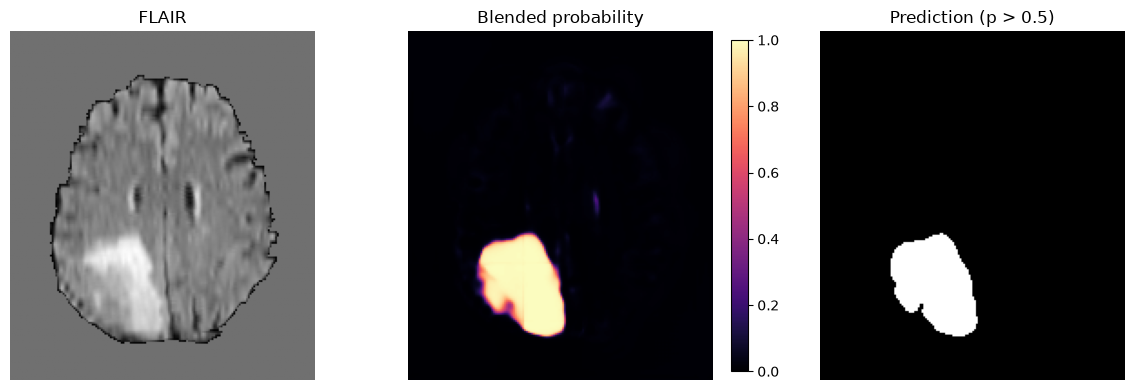

In [49]:
z = int(np.argmax(prediction.sum(axis=(0, 1))))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(image[:, :, z, 0].T.astype(np.float32), cmap="gray", origin="lower")
axes[0].set_title("FLAIR")

im = axes[1].imshow(probabilities[:, :, z].T, cmap="magma", origin="lower", vmin=0, vmax=1)
axes[1].set_title("Blended probability")

plt.colorbar(im, ax=axes[1], fraction=0.046)
axes[2].imshow(prediction[:, :, z].T, cmap="gray", origin="lower")
axes[2].set_title("Prediction (p > 0.5)")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

Full-volume predictions were made with overlapping sliding-window inference over the cropped volume. The patch size was 64x64x64 voxels and the stride was 32 voxels in every direction, which gives a 50% overlap between neighboring patches and 100 windows per volume (5x5x4). The last window along each axis is shifted back so that the whole volume is covered. The patch probabilities were combined using a Gaussian-weighted average, voxels near the center of a patch count more than voxels near its border (sigma = 0.25 x patch size). The summed probabilities were divided by the summed weights at every voxel, and only then thresholded at 0.5 to obtain the binary mask. Combining probabilities before thresholding avoids the hard seams that appear when each patch is thresholded separately, and it reduces the unreliable predictions at patch borders where the context is incomplete.

On the untouched test split, report case-wise whole-tumor Dice, IoU, sensitivity and HD95 in millimetres. Provide mean, standard deviation and median, plus the number of empty predictions.

In [50]:
def evaluate_test_cases(threshold=0.5, postprocess=None):

    rows = []

    for row in split_df[split_df["split"] == "test"].itertuples():
        spacing = nib.load(DATA_ROOT / row.label_relpath).header.get_zooms()[:3]
        reference = np.load(CACHE_DIR / f"{row.case_id}_label.npy")
        prediction = np.load(PRED_DIR / f"{row.case_id}.npy") > threshold
        if postprocess is not None:
            prediction = postprocess(prediction)
        rows.append({"case_id": row.case_id, **case_metrics(prediction, reference, spacing)})
        
    return pd.DataFrame(rows)

In [51]:
test_results = evaluate_test_cases()
test_results.to_csv(CHECKPOINT_DIR / "test_results.csv", index=False)
print(test_results[["case_id", "dice", "iou", "sensitivity", "hd95_mm"]].round(3).to_string(index=False))

  case_id  dice   iou  sensitivity  hd95_mm
BRATS_002 0.872 0.774        0.983    4.690
BRATS_012 0.845 0.732        0.752    9.274
BRATS_016 0.879 0.783        0.937    5.745
BRATS_033 0.940 0.887        0.951    2.449
BRATS_039 0.831 0.711        0.725    5.099
BRATS_050 0.925 0.861        0.903    3.606
BRATS_059 0.929 0.868        0.939    5.831
BRATS_065 0.822 0.698        0.948   12.247
BRATS_067 0.884 0.793        0.941   41.231
BRATS_078 0.532 0.362        0.815   15.297
BRATS_079 0.860 0.754        0.774    5.000
BRATS_088 0.905 0.827        0.868    6.164
BRATS_097 0.950 0.905        0.964    2.236
BRATS_108 0.830 0.710        0.761    7.810
BRATS_112 0.956 0.916        0.977   25.159
BRATS_131 0.841 0.725        0.771   12.124
BRATS_137 0.838 0.722        0.735    9.165
BRATS_141 0.832 0.712        0.733    8.602
BRATS_142 0.949 0.903        0.919    4.123
BRATS_144 0.881 0.787        0.887   39.305
BRATS_156 0.846 0.733        0.752    6.557
BRATS_158 0.861 0.756        0.7

In [52]:
metrics = ["dice", "iou", "sensitivity", "hd95_mm"]

summary = pd.DataFrame({
    "mean": test_results[metrics].mean(),
    "std": test_results[metrics].std(),
    "median": test_results[metrics].median(),
})

print(summary.round(3).to_string())
print("Number of test cases:", len(test_results))
print("Empty predictions:", int((test_results["pred_voxels"] == 0).sum()))

               mean     std  median
dice          0.851   0.103   0.872
iou           0.752   0.135   0.774
sensitivity   0.849   0.123   0.888
hd95_mm      17.555  20.272   9.274
Number of test cases: 73
Empty predictions: 0


Convert voxel counts to tumor volume in millilitres using voxel spacing. Report absolute and percentage volume error per case.

In [53]:
volume_df = test_results[["case_id", "ref_voxels", "pred_voxels"]].merge(
    geometry_df[["case_id", "image_spacing"]], on="case_id")
voxel_ml = volume_df["image_spacing"].apply(lambda s: np.prod(s) / 1000) 

volume_df["ref_volume_ml"] = volume_df["ref_voxels"] * voxel_ml
volume_df["pred_volume_ml"] = volume_df["pred_voxels"] * voxel_ml
volume_df["signed_error_ml"] = volume_df["pred_volume_ml"] - volume_df["ref_volume_ml"]
volume_df["abs_error_ml"] = volume_df["signed_error_ml"].abs()
volume_df["abs_error_pct"] = 100 * volume_df["abs_error_ml"] / volume_df["ref_volume_ml"]

print(volume_df[["case_id", "ref_volume_ml", "pred_volume_ml", "abs_error_ml", "abs_error_pct"]].round(2).to_string(index=False))

  case_id  ref_volume_ml  pred_volume_ml  abs_error_ml  abs_error_pct
BRATS_002          63.06           79.05         15.99          25.36
BRATS_012          21.61           16.87          4.74          21.94
BRATS_016          82.73           93.71         10.98          13.27
BRATS_033         114.02          116.64          2.63           2.30
BRATS_039          37.01           27.58          9.44          25.50
BRATS_050          76.24           72.58          3.66           4.80
BRATS_059          99.57          101.65          2.08           2.09
BRATS_065         166.09          216.86         50.77          30.57
BRATS_067          55.28           62.34          7.06          12.77
BRATS_078          85.08          175.55         90.47         106.33
BRATS_079          89.11           71.21         17.90          20.09
BRATS_088         253.71          232.84         20.88           8.23
BRATS_097         153.18          157.74          4.56           2.98
BRATS_108         12

In [54]:
volume_columns = ["ref_volume_ml", "pred_volume_ml", "signed_error_ml", "abs_error_ml", "abs_error_pct"]

print(pd.DataFrame({
    "mean": volume_df[volume_columns].mean(),
    "median": volume_df[volume_columns].median(),
    "max": volume_df[volume_columns].max(),
}).round(2).to_string())

print("Cases over-segmented (prediction larger than reference):", int((volume_df["signed_error_ml"] > 0).sum()), "of", len(volume_df))

                   mean  median     max
ref_volume_ml    107.39   89.11  318.35
pred_volume_ml   104.63   92.92  299.69
signed_error_ml   -2.75   -2.46   90.47
abs_error_ml      16.99   10.98   90.47
abs_error_pct     22.05   15.72  274.14
Cases over-segmented (prediction larger than reference): 34 of 73


Apply one justified connected-component postprocessing rule. Report results before and after it; do not keep the rule merely because it improves the test score.

In [55]:
VAL_PRED_DIR = CACHE_DIR / "val_probabilities"
VAL_PRED_DIR.mkdir(exist_ok=True)

for case_id in validation_cases:
    path = VAL_PRED_DIR / f"{case_id}.npy"
    if path.exists():
        continue
    image = np.load(CACHE_DIR / f"{case_id}_image.npy").astype(np.float32)
    np.save(path, predict_volume(final_model, image, DEVICE, PATCH_SIZE, STRIDE))

In [56]:
candidate_rules = {
    "none": lambda mask: mask,
    "keep largest component": keep_largest_component,
    "remove components < 1 mL": lambda mask: remove_small_components(mask, 1000),
    "remove components < 5 mL": lambda mask: remove_small_components(mask, 5000),
    "remove components < 10 mL": lambda mask: remove_small_components(mask, 10000),
}

In [57]:
rows = []

for name, rule in candidate_rules.items():
    results = pd.DataFrame([
        case_metrics(rule(np.load(VAL_PRED_DIR / f"{c}.npy") > 0.5), np.load(CACHE_DIR / f"{c}_label.npy"))
        for c in validation_cases
    ])
    rows.append({
        "rule": name, "dice": results["dice"].mean(), "sensitivity": results["sensitivity"].mean(),
        "hd95_mean": results["hd95_mm"].mean(), "hd95_median": results["hd95_mm"].median(),
        "fp_volume_ml": results["fp_volume_ml"].mean(), "empty": int((results["pred_voxels"] == 0).sum()),
    })
    
print(pd.DataFrame(rows).round(3).to_string(index=False))

                     rule  dice  sensitivity  hd95_mean  hd95_median  fp_volume_ml  empty
                     none 0.810        0.847     31.375       18.221        18.150      0
   keep largest component 0.821        0.816     14.304        7.810        12.477      0
 remove components < 1 mL 0.815        0.847     26.297       10.724        17.362      0
 remove components < 5 mL 0.815        0.836     19.707        8.062        16.222      0
remove components < 10 mL 0.809        0.828     17.980        7.810        15.453      2


In [58]:
n_ref_components = [label_components(np.load(CACHE_DIR / f"{c}_label.npy"), structure=np.ones((3, 3, 3)))[1] for c in validation_cases]

print("Reference components per validation case: median", int(np.median(n_ref_components)),
      "| cases with more than one:", sum(n > 1 for n in n_ref_components), "of", len(n_ref_components))

Reference components per validation case: median 4 | cases with more than one: 58 of 73


In [59]:
MIN_COMPONENT_VOXELS = 1000  # 1 mL at 1 mm^3 voxels

def chosen_rule(mask):
    return remove_small_components(mask, MIN_COMPONENT_VOXELS)

test_results_pp = evaluate_test_cases(postprocess=chosen_rule)

In [60]:
metrics = ["dice", "iou", "sensitivity", "hd95_mm", "fp_volume_ml"]

comparison = pd.concat({
    "before": test_results[metrics].agg(["mean", "std", "median"]).T,
    "after": test_results_pp[metrics].agg(["mean", "std", "median"]).T,
}, axis=1)

print(comparison.round(3).to_string())
print("Cases changed by the rule:", int((test_results["pred_voxels"] != test_results_pp["pred_voxels"]).sum()), "of", len(test_results))
print("Empty predictions after:", int((test_results_pp["pred_voxels"] == 0).sum()))

              before                  after               
                mean     std median    mean     std median
dice           0.851   0.103  0.872   0.854   0.103  0.875
iou            0.752   0.135  0.774   0.757   0.134  0.778
sensitivity    0.849   0.123  0.888   0.848   0.124  0.888
hd95_mm       17.555  20.272  9.274  13.484  12.914  9.055
fp_volume_ml  12.006  16.301  8.228  11.459  16.139  7.747
Cases changed by the rule: 70 of 73
Empty predictions after: 0


One connected-component rule was applied after the thresholding: connected components (26-connectivity) smaller than 1mL or a 1000 voxels were removed. The rule was chosen using the validation split, before looking at the test results. It was compared with "keeping only the largest component" and with minimum sizes of 1, 5 and 10mL.
Keeping only the largest component gave the best HD95 value but reduced the validation sensitivity from 0.847 to 0.816, because the reference masks often times have several components (58 of 73 validation cases) and this rule deletes real tumor parts. Larger size thresholds also reduced sensitivity. The 1mL rule was the only one that left the validation sensitivity unchanged (0.847) while still slightly improving the Dice (0.810 to 0.815) and the HD95 (31.4 to 26.3mm). A component smaller than 1mL is less than about 12 mm across, so it is more likely to be a stray false positive than a real part of the tumor.

On the test split the rule changed the results slightly: the mean dice went from 0.851 to 0.854, the mean sensitivity persisted at about 0.85 and the mean HD95 decreased from 17.6 to 13.5mm, while the median HD95 barely changed (9.3 to 9.1mm). The rule was selected because of the validation evidence and the reasoning given above, and not because of the test improvement.

### Part G. Three-plane error analysis and limitations

For the best, median and worst test cases by Dice, show axial, coronal and sagittal views with reference and prediction overlays.

In [61]:
ranked = test_results_pp.sort_values("dice").reset_index(drop=True)
selected = {"Best": ranked.iloc[-1], "Median": ranked.iloc[len(ranked) // 2], "Worst": ranked.iloc[0]}

In [62]:
case_data = {}
for name, row in selected.items():
    flair = np.load(CACHE_DIR / f"{row.case_id}_image.npy")[..., 0].astype(np.float32)
    reference = np.load(CACHE_DIR / f"{row.case_id}_label.npy").astype(bool)
    prediction = chosen_rule(np.load(PRED_DIR / f"{row.case_id}.npy") > 0.5)
    case_data[name] = (f"{name}: {row.case_id}\nDice {row.dice:.3f}", flair, reference, prediction)
    print(name, row.case_id, "Dice", round(row.dice, 3))

Best BRATS_451 Dice 0.963
Median BRATS_293 Dice 0.875
Worst BRATS_376 Dice 0.33


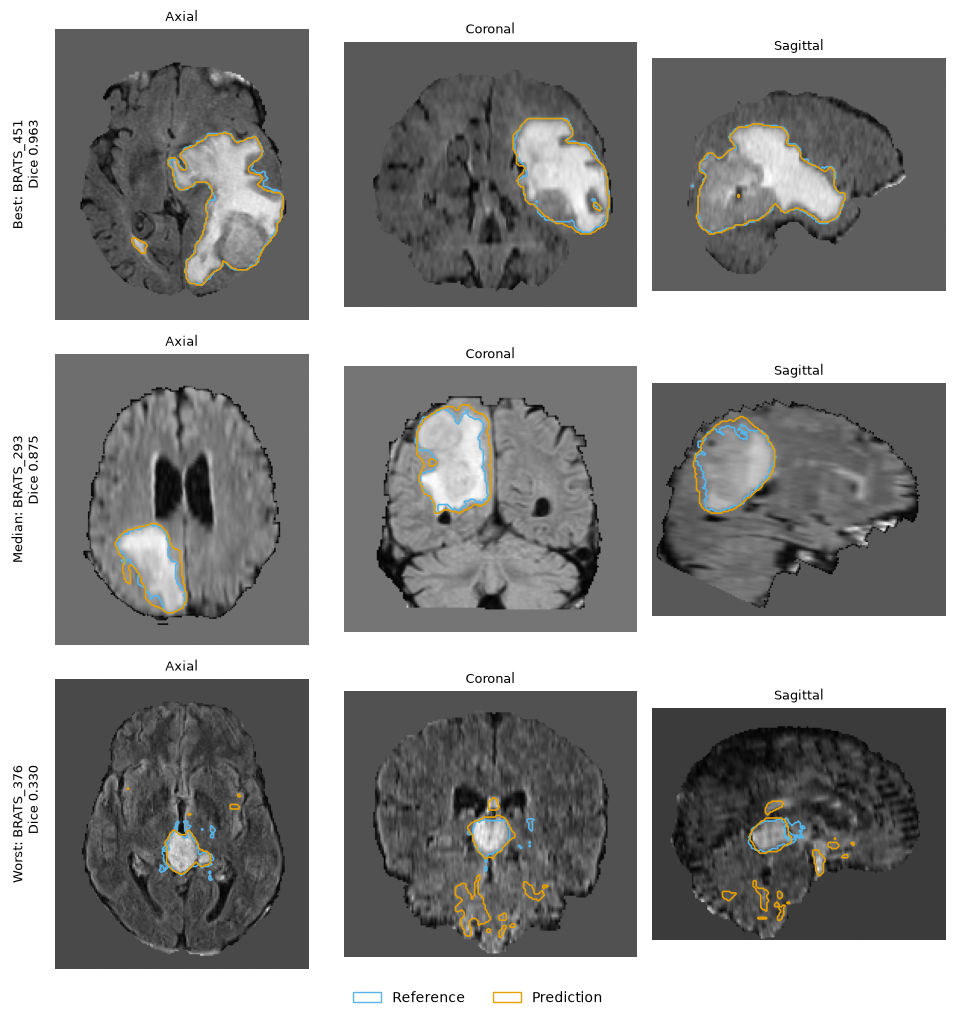

In [63]:
cases = [(title, flair, reference, prediction, centroid_point(reference))
         for title, flair, reference, prediction in case_data.values()]
plot_contour_rows(cases)

Colour true-positive, false-positive and false-negative voxels distinctly. Relate at least one error to boundary quality, small structures or patch context.

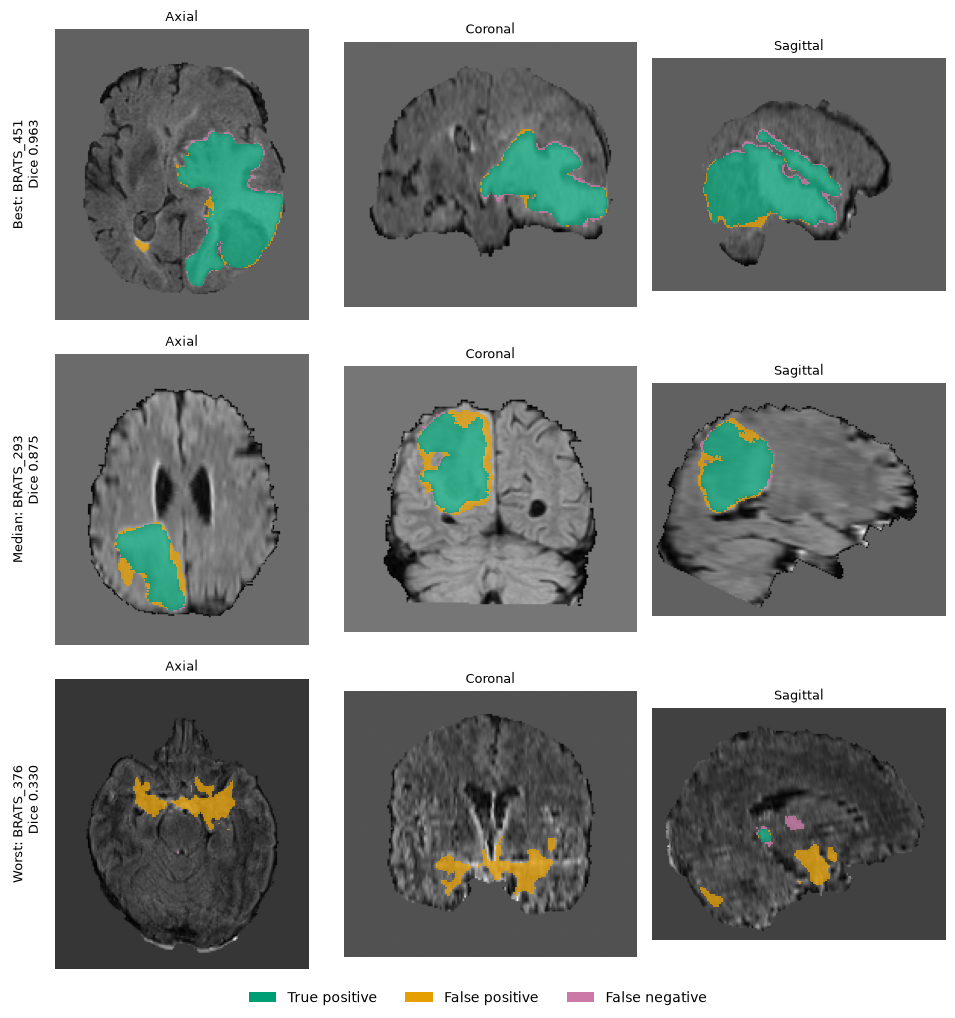

In [64]:
cases = [(title, flair, reference, prediction, largest_error_point(prediction, reference))
         for title, flair, reference, prediction in case_data.values()]
plot_error_rows(cases)

In [65]:
print(pd.DataFrame(selected).T[["case_id", "dice", "sensitivity", "fp_volume_ml", "fn_volume_ml"]].infer_objects().round(3).to_string())

          case_id   dice  sensitivity  fp_volume_ml  fn_volume_ml
Best    BRATS_451  0.963        0.964         7.343         6.643
Median  BRATS_293  0.875        0.983        16.634         1.064
Worst   BRATS_376  0.330        0.753        28.369         2.499


In the best case (BRATS_451, Dice 0.963) the errors are thin bands along the tumor boundary, with similar amounts of false-positive (7.3 mL) and false-negative (6.6 mL) volume. In the median case (BRATS_293, Dice 0.875) almost all of the tumor was found (sensitivity 0.983), but a band of false positives surrounds the tumor (16.6 mL), so the tumor is over-segmented. These are boundary errors: the edge between the edema and the normal brain is gradual in the FLAIR image and the reference boundary itself is partly subjective, so the model's boundary is often a voxel or two away from the reference.

The worst case (BRATS_376, Dice 0.330) is a small structure error. The reference tumor is small (about 10 mL) and lies near the midline, and the model also marked larger bright FLAIR regions at the skull base as tumor, giving 28.4 mL of false positives, nearly three times the size of the true tumor. As the reference tumor is small, a few false-positive regions are enough to reduce Dice a lot. The false positives are far from the tumor, which suggests the 64x64x64 patches provide too little context to tell these bright regions apart from real tumor, though this was not tested directly.

Compare Dice with HD95 and volume error for these cases. Explain why one metric cannot summarize every failure.

In [66]:
comparison_df = pd.DataFrame(selected).T.reset_index(names="case_type").infer_objects()
comparison_df = comparison_df.merge(geometry_df[["case_id", "image_spacing"]], on="case_id")
voxel_ml = comparison_df["image_spacing"].apply(lambda s: np.prod(s) / 1000)

In [67]:
comparison_df["ref_volume_ml"] = comparison_df["ref_voxels"] * voxel_ml
comparison_df["pred_volume_ml"] = comparison_df["pred_voxels"] * voxel_ml
comparison_df["volume_error_ml"] = (comparison_df["pred_volume_ml"] - comparison_df["ref_volume_ml"]).abs()
comparison_df["volume_error_pct"] = 100 * comparison_df["volume_error_ml"] / comparison_df["ref_volume_ml"]

print(comparison_df[["case_type", "case_id", "dice", "hd95_mm", "ref_volume_ml", "pred_volume_ml",
                     "volume_error_ml", "volume_error_pct"]].round(2).to_string(index=False))

case_type   case_id  dice  hd95_mm  ref_volume_ml  pred_volume_ml  volume_error_ml  volume_error_pct
     Best BRATS_451  0.96     1.41         186.26          186.96             0.70              0.38
   Median BRATS_293  0.88     4.69          63.06           78.63            15.57             24.69
    Worst BRATS_376  0.33    40.76          10.10           35.97            25.87            256.11


In [68]:
all_cases = test_results_pp.copy()
all_cases["volume_error_pct"] = 100 * (all_cases["pred_voxels"] - all_cases["ref_voxels"]).abs() / all_cases["ref_voxels"]
print(all_cases[["dice", "hd95_mm", "volume_error_pct"]].corr(method="spearman").round(2).to_string())

                  dice  hd95_mm  volume_error_pct
dice              1.00    -0.51             -0.89
hd95_mm          -0.51     1.00              0.40
volume_error_pct -0.89     0.40              1.00


The three metrics describe the three cases differently. In the best case (BRATS_451) the Dice is 0.96 and the HD95 is 1.4 mm, but the volume error is only 0.38% even though about 14 mL of voxels are misplaced (7.3 mL false positive and 6.6 mL false negative), because the extra and missing voxels cancel out. In the median case (BRATS_293) the Dice (0.88) and HD95 (4.7 mm) look acceptable, but the predicted volume is 25% too large, which shows over-segmentation. In the worst case (BRATS_376) the HD95 of 40.8 mm comes from false-positive regions far from the tumor, and the Dice of 0.33 is low because the reference tumor is small (10 mL) compared to the 28 mL of false positives. Its volume error of 256% is also inflated by the small reference volume.

One metric cannot summarize every failure because Dice measures overlap and is dominated by large structures, HD95 reacts to small distant errors, and volume error ignores where the voxels are. Across the whole test set, Dice is strongly related to volume error (Spearman rho = -0.89) but only moderately related to HD95 (rho = -0.51), so they capture different information.

State at least three limitations, including the small training budget and the lack of external-site validation.

In [69]:
split_df["label_hash"] = [hashlib.md5(np.load(CACHE_DIR / f"{c}_label.npy").tobytes()).hexdigest() for c in split_df["case_id"]]

duplicates = split_df[split_df.duplicated("label_hash", keep=False)]

pairs = duplicates.groupby("label_hash").agg(cases=("case_id", list), splits=("split", list)).reset_index(drop=True)

print("Cases sharing an identical reference mask with another case:", len(duplicates))
print(pairs.to_string())

split_df = split_df.drop(columns="label_hash")

Cases sharing an identical reference mask with another case: 12
                    cases               splits
0  [BRATS_015, BRATS_280]       [train, train]
1  [BRATS_013, BRATS_288]  [train, validation]
2  [BRATS_007, BRATS_290]       [train, train]
3  [BRATS_002, BRATS_293]         [test, test]
4  [BRATS_010, BRATS_278]       [train, train]
5  [BRATS_001, BRATS_275]       [train, train]


1. Small training budget. Each model was trained for only 1000 iterations (batch size 4, 64x64x64 patches) with a small 3D U-Net (1.4M parameters) and a constant learning rate. The losses were still decreasing at the end and the validation Dice was unstable (it fell from 0.82 to 0.73 over the last epochs of the uniform run), so the models are probably undertrained and the results are not the best that this architecture can reach.

2. No external-site validation. The training, validation and test cases all come from the same dataset (Medical Segmentation Decathlon Task01, derived from BraTS). The test set is therefore drawn from the same distribution as the training set, and the results say nothing about how the model would work on other scanners, hospitals or acquisition protocols.

3. Duplicate scans in the supplied split. Six pairs of cases have identical reference masks and the same images up to an intensity scaling (see the table above). One pair is split between training and validation (BRATS_013 and BRATS_288), which makes the validation scores very slightly optimistic, and the two test cases BRATS_002 and BRATS_293 are the same scan, so the test set has 72 independent patients instead of 73.

## Bonus Parts

### Bonus A. Missing-modality stress test

Without retraining, replace each MRI channel in turn with zeros at test time. Compare Dice, HD95 and volume error with the four-channel result. Identify the most influential channel, explain why zeroing is an imperfect simulation of a genuinely missing acquisition, and state how training could be redesigned for missing modalities.

In [70]:
def evaluate_zeroed_channel(channel):
    rows = []
    for case_id in test_cases:
        image = np.load(CACHE_DIR / f"{case_id}_image.npy").astype(np.float32)
        image[..., channel] = 0  # replace this normalized channel with zeros at test time
        reference = np.load(CACHE_DIR / f"{case_id}_label.npy")
        probabilities = predict_volume(final_model, image, DEVICE, PATCH_SIZE, STRIDE)
        rows.append({"case_id": case_id, **case_metrics(chosen_rule(probabilities > 0.5), reference)})
    return pd.DataFrame(rows)

In [71]:
BONUS_A_FILE = CHECKPOINT_DIR / "bonus_a_results.csv"
if BONUS_A_FILE.exists():
    bonus_a = pd.read_csv(BONUS_A_FILE)
else:
    baseline = test_results_pp.assign(condition="All four channels")
    zeroed = [evaluate_zeroed_channel(c).assign(condition=f"{name} zeroed") for c, name in enumerate(channel_order)]
    bonus_a = pd.concat([baseline] + zeroed, ignore_index=True)
    bonus_a.to_csv(BONUS_A_FILE, index=False)

In [72]:
bonus_a["volume_error_ml"] = (bonus_a["pred_voxels"] - bonus_a["ref_voxels"]).abs() / 1000
bonus_a["volume_error_pct"] = 100 * bonus_a["volume_error_ml"] / (bonus_a["ref_voxels"] / 1000)

In [73]:
order = ["All four channels"] + [f"{name} zeroed" for name in channel_order]
summary = bonus_a.groupby("condition").agg(
    dice_mean=("dice", "mean"), dice_median=("dice", "median"), sensitivity=("sensitivity", "mean"),
    hd95_mean=("hd95_mm", "mean"), hd95_median=("hd95_mm", "median"),
    volume_error_ml=("volume_error_ml", "mean"), volume_error_pct=("volume_error_pct", "mean"),
    empty=("pred_voxels", lambda v: int((v == 0).sum())),
).reindex(order)
print(summary.round(3).to_string())

                   dice_mean  dice_median  sensitivity  hd95_mean  hd95_median  volume_error_ml  volume_error_pct  empty
condition                                                                                                               
All four channels      0.854        0.875        0.848     13.484        9.055           16.870            21.510      0
FLAIR zeroed           0.067        0.000        0.039     31.546       26.926           99.057            94.277     44
T1w zeroed             0.828        0.857        0.898     28.711       21.095           19.338            33.032      0
t1gd zeroed            0.819        0.866        0.792     13.456        7.842           21.163            25.387      1
T2w zeroed             0.787        0.843        0.811     27.236       15.108           23.838            33.402      0


Zeroing one channel at test time, without retraining, shows that the model relies very unequally on its four inputs. FLAIR was by far the most influential channel. With FLAIR zeroed the mean Dice fell from 0.854 to 0.067, sensitivity fell to 0.039 and 44 of 73 cases had an empty prediction. This is expected because the whole-tumor reference is dominated by edema, which is bright on FLAIR. Zeroing T2w, T1ce or T1w reduced the Dice to 0.787, 0.819 and 0.828, so these channels carry smaller, complementary information. Zeroing T1w or T2w also roughly doubled the mean HD95 (13.5 to 28.7 and 27.2 mm). The FLAIR HD95 (31.5 mm) is computed only on the 29 non-empty cases, so it is not directly comparable.

Zeroing is an imperfect simulation of a missing acquisition. After normalization, zero is the average brain intensity and not the absence of signal, so the network receives a plausible but wrong value in every brain voxel, a pattern that it never saw in training. A real missing sequence would also lack the contrast it provides, while the other channels would still have their own noise and scanner differences. Training could be redesigned for missing modalities with modality dropout, where channels are randomly removed during training so that the model learns to work with whatever is available. Alternatively, separate encoders per modality with feature fusion could be used.

### Bonus B. Sliding-window seam test

Run the same trained model with 0%, 25% and 50% overlap. Compare runtime and metrics, then plot the probability difference near patch borders. Explain when overlap helps and why selecting overlap after repeatedly inspecting the test labels would bias the result.

In [74]:
overlap_strides = {"0%": 64, "25%": 48, "50%": 32}  # stride in voxels for 64^3 patches

def border_distance(shape, patch_size, stride):
    distance = np.full(shape, np.inf, dtype=np.float32)

    for axis in range(3):
        starts = window_starts(shape[axis], patch_size[axis], stride)
        edges = sorted(set(starts[1:]) | {s + patch_size[axis] for s in starts[:-1]})
        axis_distance = np.abs(np.arange(shape[axis])[:, None] - (np.array(edges)[None, :] - 0.5)).min(axis=1)
        broadcast_shape = [1, 1, 1]
        broadcast_shape[axis] = shape[axis]
        distance = np.minimum(distance, axis_distance.reshape(broadcast_shape))

    return distance

In [75]:
EXAMPLE_CASE = test_cases[0]
n_bins = 32
profile_sum, profile_count = np.zeros(n_bins), np.zeros(n_bins)
rows = []

for case_id in test_cases:
    image = np.load(CACHE_DIR / f"{case_id}_image.npy").astype(np.float32)
    reference = np.load(CACHE_DIR / f"{case_id}_label.npy")
    probabilities = {}

    for name, stride in overlap_strides.items():
        start = time.perf_counter()
        probabilities[name] = predict_volume(final_model, image, DEVICE, PATCH_SIZE, (stride,) * 3)
        runtime = time.perf_counter() - start
        rows.append({"overlap": name, "case_id": case_id, "runtime_s": runtime,
                     **case_metrics(chosen_rule(probabilities[name] > 0.5), reference)})

    difference = np.abs(probabilities["0%"] - probabilities["50%"])
    distance = border_distance(difference.shape, PATCH_SIZE, 64)
    brain = image[..., 0] != 0

    bins = np.minimum(distance[brain].astype(int), n_bins - 1)
    profile_sum += np.bincount(bins, weights=difference[brain], minlength=n_bins)
    profile_count += np.bincount(bins, minlength=n_bins)
    
    if case_id == EXAMPLE_CASE:
        example_difference, example_distance = difference, distance

bonus_b = pd.DataFrame(rows)
boundary_profile = profile_sum / profile_count

In [76]:
bonus_b["volume_error_ml"] = (bonus_b["pred_voxels"] - bonus_b["ref_voxels"]).abs() / 1000

summary = bonus_b.groupby("overlap").agg(
    runtime_s=("runtime_s", "mean"), dice_mean=("dice", "mean"), hd95_mean=("hd95_mm", "mean"),
    sensitivity=("sensitivity", "mean"), volume_error_ml=("volume_error_ml", "mean"),
).reindex(list(overlap_strides))

summary.insert(0, "windows_per_volume", [27, 48, 100])

print(summary.round(3).to_string())

         windows_per_volume  runtime_s  dice_mean  hd95_mean  sensitivity  volume_error_ml
overlap                                                                                   
0%                       27      0.313      0.809     19.863        0.787           21.643
25%                      48      0.540      0.839     16.358        0.826           17.258
50%                     100      1.198      0.854     13.484        0.848           16.870


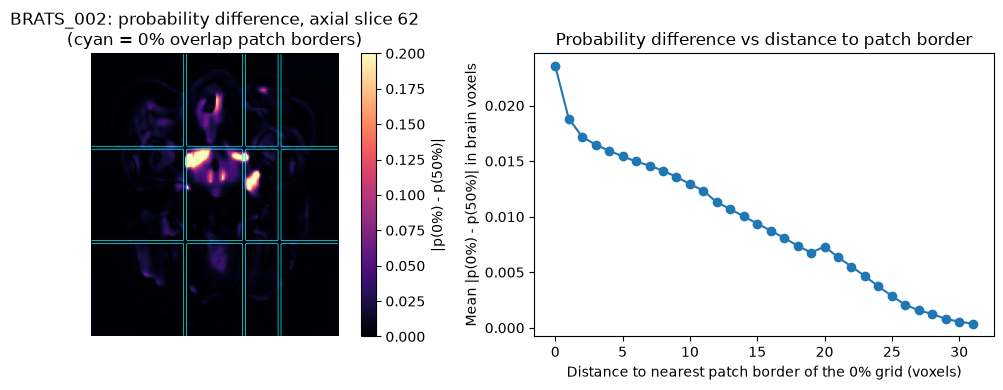

In [77]:
z = int(np.argmax(example_difference.sum(axis=(0, 1))))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

im = axes[0].imshow(example_difference[:, :, z].T, cmap="magma", origin="lower", vmin=0, vmax=0.2)
axes[0].contour((example_distance[:, :, z] < 1).T, levels=[0.5], colors="cyan", linewidths=0.5)
plt.colorbar(im, ax=axes[0], fraction=0.046, label="|p(0%) - p(50%)|")
axes[0].set_title(f"{EXAMPLE_CASE}: probability difference, axial slice {z}\n(cyan = 0% overlap patch borders)")
axes[0].axis("off")

axes[1].plot(np.arange(n_bins), boundary_profile, marker="o")
axes[1].set_xlabel("Distance to nearest patch border of the 0% grid (voxels)")
axes[1].set_ylabel("Mean |p(0%) - p(50%)| in brain voxels")
axes[1].set_title("Probability difference vs distance to patch border")
plt.tight_layout()
plt.show()

Increasing the overlap from 0% to 50% raised the mean test Dice from 0.809 to 0.854 and lowered the mean HD95 from 19.9 to 13.5 mm, but the runtime per volume rose from 0.31 s to 1.20 s (27 versus 100 windows). The 25% overlap was in between (Dice 0.839, 0.54 s). The probability difference between 0% and 50% overlap was largest at the patch borders of the 0% grid (mean 0.024) and fell to 0.0004 at the patch center, so the differences are concentrated along the seams. Voxels near a patch border have less context and see the zero padding of the convolutions, so their predictions are less reliable. Overlap helps most when structures cross patch borders, as large tumors do, because the Gaussian blending predicts each voxel mainly from the patches where it is near the center. It helps less for small structures that lie inside one patch, and it costs more runtime.

The 50% overlap was fixed in advance and used for all main results, so this comparison is only a sensitivity analysis. If the overlap were chosen after repeatedly inspecting the test labels, the choice would be tuned to this specific test set, so the test scores would be optimistically biased and no longer an honest estimate for unseen data. The overlap should be selected on the validation split.